# Model summary on held-out test data

- This notebook scores the models already built in the project on `data/test.csv.gz`.
- No new model is specified. The training code is copied from the notebooks that already trained these models.
- Fitted estimators were not saved. `scores/val_t_learner.npy` and `scores/val_transformed_outcome.npy` are validation predictions. This notebook reruns the same training code on the training split, checks those saved validation scores, and then scores the test file once.
- Test rows are not used to fit a model or to choose a setting.
- Features are only `f0` through `f11`. `exposure` is not a feature, and rows are not filtered on exposure.
- Every ranking uses `src/uplift_eval.py`. `uplift_by_group` reports counts, visit counts, visit rates, uplift, and a 95% confidence interval.
- Uplift is the treatment visit rate minus the control visit rate. Incremental visits are the group size times that uplift.
- A pair of models is a tie when the 95% intervals overlap by more than half of the narrower interval.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, Ridge
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.uplift_eval import (
    FEATURE_COLUMNS,
    area_above_random,
    cumulative_uplift,
    overall_itt,
    percent_view,
    plot_cumulative,
    plot_uplift_by_group,
    uplift_by_group,
)

RANDOM_SEED = 2026
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 30)

train_df = pd.read_csv(ROOT / "data" / "train.csv.gz")
validation_df = pd.read_csv(ROOT / "data" / "validation.csv.gz")
test_df = pd.read_csv(ROOT / "data" / "test.csv.gz")

assert list(FEATURE_COLUMNS) == [f"f{i}" for i in range(12)]
assert set(FEATURE_COLUMNS).isdisjoint({"treatment", "exposure", "visit", "conversion"})
assert len(train_df) == 700_000
assert len(validation_df) == 150_000
assert len(test_df) == 150_000

print("Held-out test summary")
print("Training code is the code already used in the project notebooks.")
print(f"Train rows: {len(train_df):,}")
print(f"Validation rows: {len(validation_df):,}")
print(f"Test rows: {len(test_df):,}")
print("Features: " + ", ".join(FEATURE_COLUMNS))
print("exposure is excluded, and no row is dropped because of exposure.")


Held-out test summary
Training code is the code already used in the project notebooks.
Train rows: 700,000
Validation rows: 150,000
Test rows: 150,000
Features: f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11
exposure is excluded, and no row is dropped because of exposure.


## Existing models

- **T-learner**, from `notebooks/t_learner.ipynb`. Separate logistic regressions on the training treatment rows and the training control rows. `C` is chosen inside each training arm from `0.001, 0.01, 0.1, 1, 10` by 5-fold stratified cross-validation. The score is the treatment probability minus the control probability.
- **Transformed outcome**, from `transformed_outcome_model.ipynb` and `notebooks/02_transformed_outcome_model.ipynb`. `p` is the training treatment rate. `Z = visit * (treatment - p) / (p * (1 - p))`. A standardized ridge regression with `alpha=100` predicts `Z`.
- **Response model**, from `notebooks/01_standard_model.ipynb` and `notebooks/model_comparison.ipynb`. A standardized logistic regression fit on training treatment rows only. The score is the predicted probability of a visit under treatment, applied to every test row.
- **Random ranking**, from `notebooks/random_baseline.ipynb` and `notebooks/model_comparison.ipynb`. One draw from `Generator(2026)`. It uses no features.


In [2]:
# Replay the existing training code on the training split only.
# Test visit and treatment are not inputs to fit or to predict.
X_train = train_df[FEATURE_COLUMNS]
y_train = train_df["visit"]
treatment_train = train_df["treatment"].eq(1)

# Response model: notebooks/01_standard_model.ipynb and notebooks/model_comparison.ipynb.
response_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
)
response_model.fit(X_train.loc[treatment_train], y_train.loc[treatment_train])

# T-learner: notebooks/t_learner.ipynb.
def fit_regularized_logreg(frame):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    model = make_pipeline(
        StandardScaler(),
        LogisticRegressionCV(
            Cs=[0.001, 0.01, 0.1, 1, 10],
            cv=cv,
            scoring="neg_log_loss",
            max_iter=1000,
        ),
    )
    return model.fit(frame[FEATURE_COLUMNS], frame["visit"])

t_learner_treatment = fit_regularized_logreg(train_df.loc[treatment_train])
t_learner_control = fit_regularized_logreg(train_df.loc[~treatment_train])
print("T-learner chosen C, treatment arm:", float(t_learner_treatment[-1].C_[0]))
print("T-learner chosen C, control arm:", float(t_learner_control[-1].C_[0]))

# Transformed outcome: transformed_outcome_model.ipynb and notebooks/02_transformed_outcome_model.ipynb.
treatment_probability = float(train_df["treatment"].mean())
transformed_target = y_train.to_numpy() * (
    (train_df["treatment"].to_numpy() - treatment_probability)
    / (treatment_probability * (1.0 - treatment_probability))
)
transformed_model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=100.0, random_state=42)),
    ]
)
transformed_model.fit(X_train, transformed_target)
print(f"Training treatment rate p: {treatment_probability:.6f}")

def t_learner_scores(frame):
    features = frame[FEATURE_COLUMNS]
    return (
        t_learner_treatment.predict_proba(features)[:, 1]
        - t_learner_control.predict_proba(features)[:, 1]
    )

saved_t = np.load(ROOT / "scores" / "val_t_learner.npy")
saved_z = np.load(ROOT / "scores" / "val_transformed_outcome.npy")
replay_t = t_learner_scores(validation_df)
replay_z = transformed_model.predict(validation_df[FEATURE_COLUMNS])
t_learner_val_diff = float(np.max(np.abs(replay_t - saved_t)))
transformed_val_diff = float(np.max(np.abs(replay_z - saved_z)))
print(f"T-learner vs scores/val_t_learner.npy, max abs diff: {t_learner_val_diff:.6g}")
print(f"Transformed outcome vs scores/val_transformed_outcome.npy, max abs diff: {transformed_val_diff:.6g}")

X_test = test_df[FEATURE_COLUMNS]
test_scores = {
    "T-learner": t_learner_scores(test_df),
    "Transformed outcome": transformed_model.predict(X_test),
    "Response model": response_model.predict_proba(X_test)[:, 1],
    "Random": np.random.default_rng(RANDOM_SEED).random(len(test_df)),
}
for name, scores in test_scores.items():
    if len(scores) != len(test_df) or not np.isfinite(scores).all():
        raise ValueError(f"Bad test scores for {name}")

print(f"Test rows scored: {len(test_df):,}")
print("Models fit on test rows: no")


T-learner chosen C, treatment arm: 0.1
T-learner chosen C, control arm: 1.0
Training treatment rate p: 0.849953
T-learner vs scores/val_t_learner.npy, max abs diff: 2.46692e-13
Transformed outcome vs scores/val_transformed_outcome.npy, max abs diff: 5.55112e-17
Test rows scored: 150,000
Models fit on test rows: no


## Uplift by group on held-out test data

- Group 1 is the highest-scoring tenth of the test file. Each group has about 15,000 records.
- The printed rates and uplift values are percentage points.
- The orange line in the charts is the overall test intention-to-treat effect.


In [3]:
test_treatment = test_df["treatment"].to_numpy()
test_visit = test_df["visit"].to_numpy()
test_itt = overall_itt(test_treatment, test_visit)

print("Overall intention-to-treat effect on held-out test data")
print(
    f"Records: {test_itt['n']:,} "
    f"(treatment {test_itt['n_treatment']:,}, control {test_itt['n_control']:,})"
)
print(
    f"Visits: treatment {test_itt['visits_treatment']:,}, "
    f"control {test_itt['visits_control']:,}"
)
print(
    f"Visit rate: treatment {test_itt['treatment_rate'] * 100:.2f}%, "
    f"control {test_itt['control_rate'] * 100:.2f}%"
)
print(
    f"Uplift: {test_itt['uplift'] * 100:.2f} percentage points "
    f"(95% CI {test_itt['ci_low'] * 100:.2f} to {test_itt['ci_high'] * 100:.2f})"
)
print(
    f"Incremental visits: {test_itt['incremental_visits']:.0f} "
    f"(95% CI {test_itt['incremental_ci_low']:.0f} to {test_itt['incremental_ci_high']:.0f})"
)

test_tables = {}
test_curves = {}
for name, scores in test_scores.items():
    test_tables[name] = uplift_by_group(scores, test_treatment, test_visit)
    test_curves[name] = cumulative_uplift(scores, test_treatment, test_visit)
    print(f"\n{name}: uplift by group on held-out test data")
    print("Counts are records and visits. Rates, uplift, and interval bounds are percentage points.")
    display(percent_view(test_tables[name]))


Overall intention-to-treat effect on held-out test data
Records: 150,000 (treatment 127,493, control 22,507)
Visits: treatment 6,170, control 871
Visit rate: treatment 4.84%, control 3.87%
Uplift: 0.97 percentage points (95% CI 0.69 to 1.25)
Incremental visits: 1454 (95% CI 1037 to 1872)

T-learner: uplift by group on held-out test data
Counts are records and visits. Rates, uplift, and interval bounds are percentage points.


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12963,2037,3328,396,25.673,19.440,6.233,4.357,8.109,934.9,653.5,1216.3
1,2,15000,12727,2273,768,113,6.034,4.971,1.063,0.078,2.048,159.5,11.7,307.2
2,3,15000,12699,2301,265,70,2.087,3.042,-0.955,-1.700,-0.211,-143.3,-255.0,-31.6
3,4,15000,12721,2279,202,37,1.588,1.624,-0.036,-0.598,0.527,-5.3,-89.7,79.0
4,5,15000,12739,2261,121,19,0.950,0.840,0.110,-0.303,0.522,16.4,-45.4,78.3
5,6,15000,12682,2318,64,10,0.505,0.431,0.073,-0.221,0.367,11.0,-33.1,55.1
6,7,15000,12762,2238,73,19,0.572,0.849,-0.277,-0.679,0.125,-41.5,-101.8,18.8
7,8,15000,12740,2260,66,11,0.518,0.487,0.031,-0.282,0.344,4.7,-42.2,51.6
8,9,15000,12667,2333,27,2,0.213,0.086,0.127,-0.016,0.271,19.1,-2.4,40.6
9,10,15000,12793,2207,1256,194,9.818,8.790,1.028,-0.261,2.317,154.1,-39.2,347.5



Transformed outcome: uplift by group on held-out test data
Counts are records and visits. Rates, uplift, and interval bounds are percentage points.


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12978,2022,3446,410,26.553,20.277,6.276,4.366,8.186,941.4,654.8,1227.9
1,2,15000,12732,2268,1539,253,12.088,11.155,0.932,-0.482,2.346,139.9,-72.2,352.0
2,3,15000,12752,2248,552,85,4.329,3.781,0.548,-0.316,1.412,82.1,-47.5,211.7
3,4,15000,12701,2299,209,36,1.646,1.566,0.080,-0.474,0.633,11.9,-71.1,95.0
4,5,15000,12698,2302,101,15,0.795,0.652,0.144,-0.219,0.507,21.6,-32.9,76.0
5,6,15000,12669,2331,69,24,0.545,1.030,-0.485,-0.914,-0.056,-72.7,-137.2,-8.3
6,7,15000,12764,2236,80,17,0.627,0.760,-0.134,-0.519,0.252,-20.0,-77.8,37.8
7,8,15000,12759,2241,42,5,0.329,0.223,0.106,-0.113,0.325,15.9,-17.0,48.8
8,9,15000,12689,2311,15,1,0.118,0.043,0.075,-0.029,0.179,11.2,-4.3,26.8
9,10,15000,12751,2249,117,25,0.918,1.112,-0.194,-0.658,0.270,-29.1,-98.7,40.5



Response model: uplift by group on held-out test data
Counts are records and visits. Rates, uplift, and interval bounds are percentage points.


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12881,2119,4649,646,36.092,30.486,5.606,3.477,7.734,840.9,521.6,1160.1
1,2,15000,12738,2262,960,135,7.537,5.968,1.568,0.490,2.647,235.3,73.5,397.0
2,3,15000,12753,2247,240,32,1.882,1.424,0.458,-0.086,1.002,68.7,-12.9,150.2
3,4,15000,12710,2290,100,18,0.787,0.786,0.001,-0.392,0.394,0.1,-58.8,59.1
4,5,15000,12739,2261,68,8,0.534,0.354,0.180,-0.096,0.455,27.0,-14.3,68.3
5,6,15000,12711,2289,31,7,0.244,0.306,-0.062,-0.304,0.180,-9.3,-45.6,27.0
6,7,15000,12767,2233,20,6,0.157,0.269,-0.112,-0.337,0.113,-16.8,-50.6,17.0
7,8,15000,12715,2285,24,4,0.189,0.175,0.014,-0.174,0.201,2.1,-26.0,30.1
8,9,15000,12760,2240,20,3,0.157,0.134,0.023,-0.143,0.189,3.4,-21.5,28.4
9,10,15000,12719,2281,58,12,0.456,0.526,-0.070,-0.389,0.249,-10.5,-58.4,37.4



Random: uplift by group on held-out test data
Counts are records and visits. Rates, uplift, and interval bounds are percentage points.


,group,n,n_treatment,n_control,visits_treatment,visits_control,treatment_rate,control_rate,uplift,ci_low,ci_high,incremental_visits,incremental_ci_low,incremental_ci_high
0,1,15000,12722,2278,620,78,4.873,3.424,1.449,0.614,2.285,217.4,92.1,342.7
1,2,15000,12789,2211,621,87,4.856,3.935,0.921,0.029,1.813,138.1,4.3,271.9
2,3,15000,12718,2282,606,78,4.765,3.418,1.347,0.514,2.179,202.0,77.2,326.9
3,4,15000,12764,2236,620,89,4.857,3.980,0.877,-0.015,1.769,131.6,-2.2,265.4
4,5,15000,12777,2223,616,89,4.821,4.004,0.818,-0.078,1.713,122.6,-11.7,257.0
5,6,15000,12803,2197,605,91,4.725,4.142,0.583,-0.327,1.494,87.5,-49.1,224.1
6,7,15000,12705,2295,643,91,5.061,3.965,1.096,0.211,1.981,164.4,31.7,297.1
7,8,15000,12631,2369,623,114,4.932,4.812,0.120,-0.821,1.061,18.0,-123.1,159.2
8,9,15000,12798,2202,603,71,4.712,3.224,1.487,0.663,2.311,223.1,99.5,346.7
9,10,15000,12786,2214,613,83,4.794,3.749,1.045,0.172,1.919,156.8,25.8,287.9


## Charts on held-out test data

- Each panel is one existing ranking, scored on the test file.
- The point is the group uplift. The bar is the 95% confidence interval.
- The cumulative chart adds estimated incremental visits from the highest score downward.
- The dashed line is the straight path a ranking with no information would follow on average.


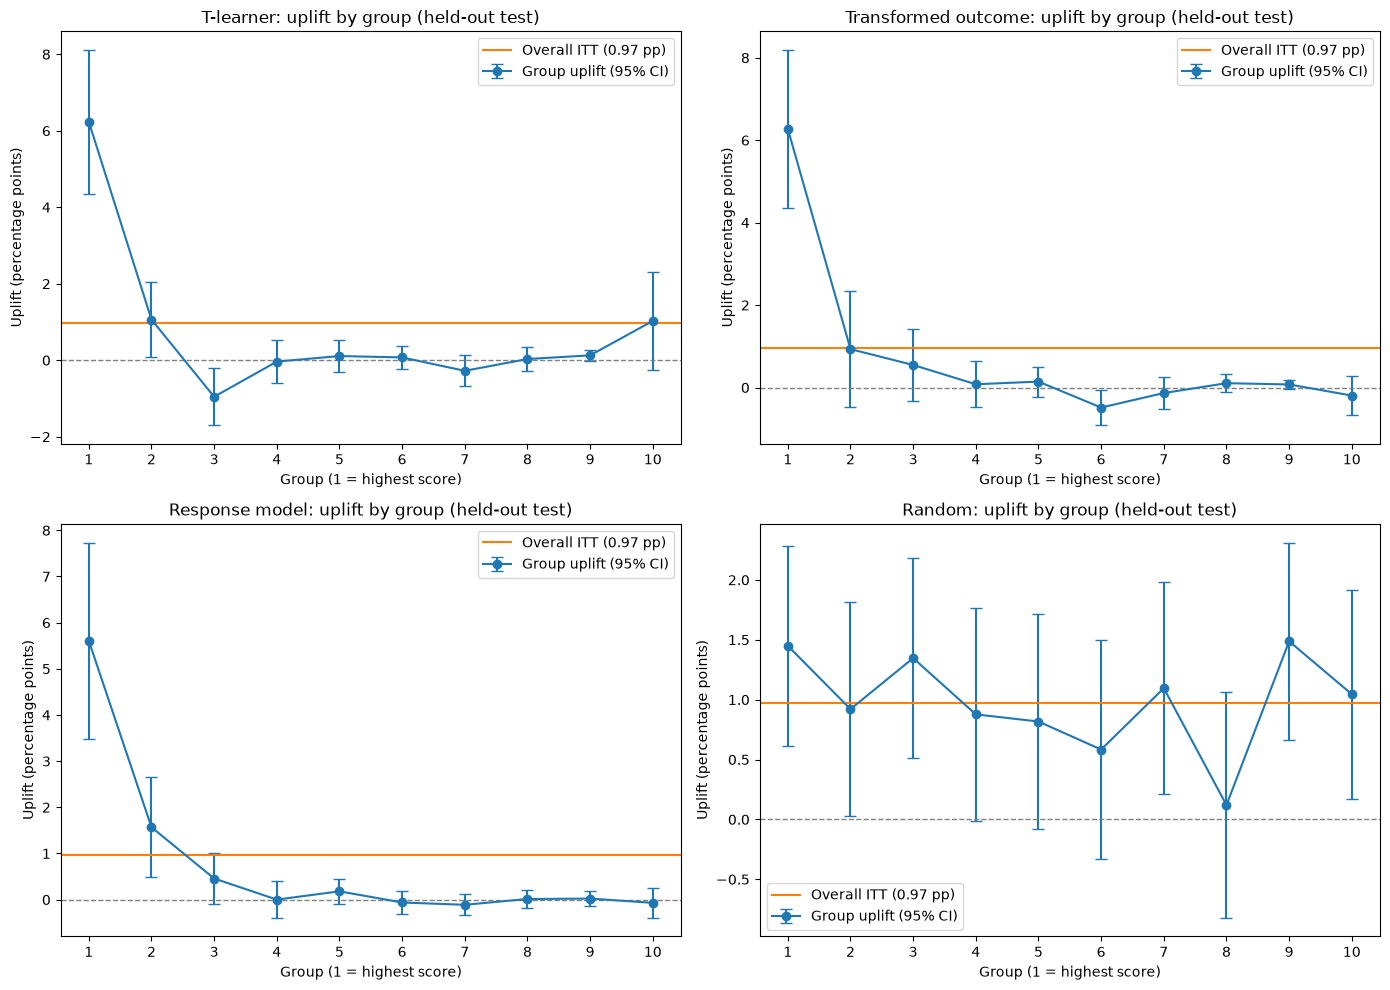

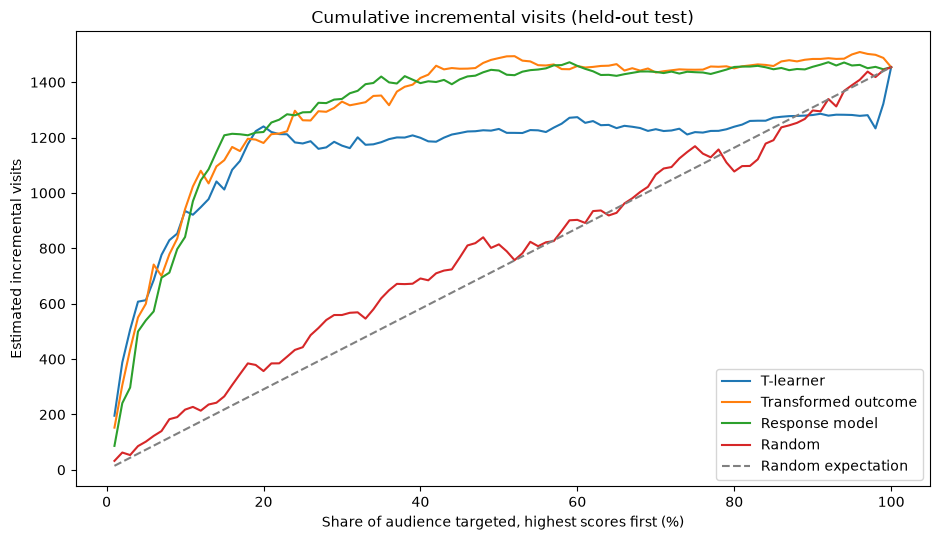

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, table) in zip(axes.ravel(), test_tables.items()):
    plot_uplift_by_group(
        table,
        itt=test_itt,
        title=f"{name}: uplift by group (held-out test)",
        ax=ax,
    )
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 5.5))
plot_cumulative(
    test_curves,
    title="Cumulative incremental visits (held-out test)",
    ax=ax,
    show_ci=False,
)
fig.tight_layout()
plt.show()


## Which test differences are ties

- The comparison uses the top tenth and the top 30 percent of each ranking.
- Overlap of more than half of the narrower 95% interval is called a tie.
- This is the same overlap rule used in `notebooks/model_comparison.ipynb`, applied here to the test file.


In [5]:
def interval_calls(summary, low_col, high_col, value_col):
    """Tie when the 95% intervals overlap by more than half of the narrower interval."""
    rows = []
    names = list(summary.index)
    for i, left in enumerate(names):
        for right in names[i + 1 :]:
            overlap_low = max(summary.loc[left, low_col], summary.loc[right, low_col])
            overlap_high = min(summary.loc[left, high_col], summary.loc[right, high_col])
            overlap = overlap_high - overlap_low
            narrower = min(
                summary.loc[left, high_col] - summary.loc[left, low_col],
                summary.loc[right, high_col] - summary.loc[right, low_col],
            )
            share = max(overlap, 0) / narrower
            rows.append(
                {
                    "model A": left,
                    "model B": right,
                    "difference (A - B)": summary.loc[left, value_col] - summary.loc[right, value_col],
                    "CIs overlap?": bool(overlap > 0),
                    "overlap as share of narrower CI": share,
                    "call": "TIE" if overlap > 0 and share > 0.5 else "possible difference",
                }
            )
    return pd.DataFrame(rows)


summary_rows = []
for name, table in test_tables.items():
    top30 = test_curves[name].iloc[(test_curves[name]["fraction_targeted"] - 0.3).abs().argmin()]
    summary_rows.append(
        {
            "model": name,
            "top_group_uplift_pp": table["uplift"].iloc[0] * 100,
            "top_group_ci_low_pp": table["ci_low"].iloc[0] * 100,
            "top_group_ci_high_pp": table["ci_high"].iloc[0] * 100,
            "top_group_incremental_visits": table["incremental_visits"].iloc[0],
            "top_group_inc_ci_low": table["incremental_ci_low"].iloc[0],
            "top_group_inc_ci_high": table["incremental_ci_high"].iloc[0],
            "top_30pct_incremental_visits": top30["incremental_visits"],
            "top_30pct_ci_low": top30["incremental_ci_low"],
            "top_30pct_ci_high": top30["incremental_ci_high"],
            "area_above_random": area_above_random(test_curves[name]),
        }
    )
test_summary = pd.DataFrame(summary_rows).set_index("model")
test_ties_group = interval_calls(
    test_summary,
    "top_group_ci_low_pp",
    "top_group_ci_high_pp",
    "top_group_uplift_pp",
)
test_ties_top30 = interval_calls(
    test_summary,
    "top_30pct_ci_low",
    "top_30pct_ci_high",
    "top_30pct_incremental_visits",
)

print("Held-out test summary (uplift in percentage points, incremental visits as counts)")
display(test_summary.round(2))
print("Ties on top-group uplift, held-out test (percentage points)")
display(test_ties_group.round(3))
print("Ties on incremental visits in the top 30%, held-out test")
display(test_ties_top30.round(3))


Held-out test summary (uplift in percentage points, incremental visits as counts)


,top_group_uplift_pp,top_group_ci_low_pp,top_group_ci_high_pp,top_group_incremental_visits,top_group_inc_ci_low,top_group_inc_ci_high,top_30pct_incremental_visits,top_30pct_ci_low,top_30pct_ci_high,area_above_random
model,,,,,,,,,,
T-learner,6.23,4.36,8.11,934.91,653.52,1216.29,1170.85,832.57,1509.14,0.29
Transformed outcome,6.28,4.37,8.19,941.35,654.83,1227.87,1329.85,948.43,1711.27,0.40
Response model,5.61,3.48,7.73,840.88,521.62,1160.13,1339.53,949.02,1730.05,0.39
Random,1.45,0.61,2.28,217.41,92.12,342.70,559.16,337.55,780.76,0.03


Ties on top-group uplift, held-out test (percentage points)


,model A,model B,difference (A - B),CIs overlap?,overlap as share of narrower CI,call
0,T-learner,Transformed outcome,-0.043,True,0.998,TIE
1,T-learner,Response model,0.627,True,0.900,TIE
2,T-learner,Random,4.783,False,0.000,possible difference
3,Transformed outcome,Response model,0.670,True,0.882,TIE
4,Transformed outcome,Random,4.826,False,0.000,possible difference
5,Response model,Random,4.156,False,0.000,possible difference


Ties on incremental visits in the top 30%, held-out test


,model A,model B,difference (A - B),CIs overlap?,overlap as share of narrower CI,call
0,T-learner,Transformed outcome,-158.996,True,0.829,TIE
1,T-learner,Response model,-168.681,True,0.828,TIE
2,T-learner,Random,611.693,False,0.000,possible difference
3,Transformed outcome,Response model,-9.685,True,0.999,TIE
4,Transformed outcome,Random,770.690,False,0.000,possible difference
5,Response model,Random,780.375,False,0.000,possible difference


## What the test file shows

- Replaying the T-learner on the validation file matches `scores/val_t_learner.npy` (max absolute difference 2.47e-13). Replaying the transformed-outcome model matches `scores/val_transformed_outcome.npy` (max absolute difference 5.55e-17).
- The test file has 150,000 records: 127,493 assigned to the campaign and 22,507 held as control.
- Assigned records visited at 4.84% (6,170 visits). Control records visited at 3.87% (871 visits).
- The intention-to-treat effect is **0.97 percentage points** (95% CI 0.69 to 1.25).
- That is **1,454 incremental visits** in this file (95% CI 1,037 to 1,872).

## Top of each ranking

- **T-learner:** top-tenth uplift 6.23 percentage points (95% CI 4.36 to 8.11), 935 incremental visits (95% CI 654 to 1,216). Top 30 percent: 1,171 incremental visits (95% CI 833 to 1,509).
- **Transformed outcome:** top-tenth uplift 6.28 percentage points (95% CI 4.37 to 8.19), 941 incremental visits (95% CI 655 to 1,228). Top 30 percent: 1,330 incremental visits (95% CI 948 to 1,711).
- **Response model:** top-tenth uplift 5.61 percentage points (95% CI 3.48 to 7.73), 841 incremental visits (95% CI 522 to 1,160). Top 30 percent: 1,340 incremental visits (95% CI 949 to 1,730).
- **Random:** top-tenth uplift 1.45 percentage points (95% CI 0.61 to 2.28), 217 incremental visits (95% CI 92 to 343). Top 30 percent: 559 incremental visits (95% CI 338 to 781).
- For the three fitted models, the top tenth holds about 58 to 65 percent of the file's incremental visits.
- The top 30 percent holds about 81 to 92 percent.

## Ties

- On top-tenth uplift, in percentage points:
  - T-learner vs Transformed outcome: difference -0.04, overlap share 1.00, **TIE**.
  - T-learner vs Response model: difference 0.6, overlap share 0.90, **TIE**.
  - T-learner vs Random: difference 4.8, overlap share 0.00, **possible difference**.
  - Transformed outcome vs Response model: difference 0.7, overlap share 0.88, **TIE**.
  - Transformed outcome vs Random: difference 4.8, overlap share 0.00, **possible difference**.
  - Response model vs Random: difference 4.2, overlap share 0.00, **possible difference**.
- On incremental visits in the top 30 percent:
  - T-learner vs Transformed outcome: difference -159.0, overlap share 0.83, **TIE**.
  - T-learner vs Response model: difference -168.7, overlap share 0.83, **TIE**.
  - T-learner vs Random: difference 611.7, overlap share 0.00, **possible difference**.
  - Transformed outcome vs Response model: difference -9.7, overlap share 1.00, **TIE**.
  - Transformed outcome vs Random: difference 770.7, overlap share 0.00, **possible difference**.
  - Response model vs Random: difference 780.4, overlap share 0.00, **possible difference**.

## Second tenth and groups below zero

- **T-learner** group 2: 1.06 percentage points (95% CI 0.08 to 2.05). The interval is above zero.
- **Transformed outcome** group 2: 0.93 percentage points (95% CI -0.48 to 2.35). The interval includes zero.
- **Response model** group 2: 1.57 percentage points (95% CI 0.49 to 2.65). The interval is above zero.
- **Random** group 2: 0.92 percentage points (95% CI 0.03 to 1.81). The interval is above zero.
- **T-learner** group 3: -0.96 percentage points (95% CI -1.70 to -0.21).
- **Transformed outcome** group 6: -0.48 percentage points (95% CI -0.91 to -0.06).

## What this means for SolePeak and MarketBridge

- The results support **targeted** delivery.
- SolePeak's extra visits are concentrated in the highest-ranked tenth. The top 30 percent still gathers most of the measured incremental visits, and the three model intervals overlap there.
- A broader, full-audience buy would keep spending on groups whose own intervals include zero.
- Skipping the campaign is not supported. The overall assignment effect is above zero, and the top tenth of each fitted model is above the random ranking.
- The T-learner, the transformed-outcome model, and the response model are a tie on this test file. MarketBridge can use any of the three rankings. The gap between them is smaller than the width of the intervals. Each group has only about 2,200 control records, which is why the intervals are wide.
- Publish the group counts, visit rates, uplift, and intervals. Keep individual scores inside the measurement workflow.

## Why this is an intention-to-treat effect

- `treatment` is random assignment to the campaign. In the scenario, MarketBridge marks a customer as eligible to receive SolePeak's advertisement.
- The measured gap includes assigned customers who were never shown the ad. Assigned customers stay in the treatment arm whether or not an impression was delivered.
- This is the intention-to-treat effect of assignment.
- `exposure` records whether the ad was shown. That happens after assignment, and only inside the treatment arm.
- The effect of seeing the ad is a different question. Seeing the ad was not randomized. Restricting the file to `exposure = 1` would drop assigned customers the delivery system did not reach, and that remaining gap would mix the impression with who was selected for delivery.
- SolePeak should quote the effect of being assigned to the campaign, inside the targeted group, with the interval.

## How response prediction differs from incrementality

- The response model estimates the probability of a visit if the record is assigned to the campaign. A high score means the record looks like a visitor.
- In the response model's top tenth, assigned records visited at 36.09% and control records visited at 30.49%. The incremental effect is the 5.61 percentage-point gap, not the 36.09% visit rate.
- The T-learner estimates the change in visit probability: the treatment model's probability minus the control model's probability.
- The transformed-outcome model estimates that same change by predicting `Z`.
- The T-learner's lowest tenth visited at 9.82% when assigned and 8.79% when not. Its uplift interval is -0.26 to 2.32 percentage points. Those are relatively frequent visitors with little measured change from assignment, so the uplift score ranks them last.
- On this test file the response ranking and the uplift rankings tie. The people with the highest chance of visiting were also the people with the largest measured gap. That tie is a result on this file. A high response score is still a prediction of a visit, not proof that the campaign caused the visit.
- MarketBridge should judge a ranking by the treatment-minus-control gap in the targeted group. SolePeak should read the visit rate as who shows up, and the uplift as how many of those visits are associated with assignment.

## What these results cannot establish

- `f0` through `f11` are anonymous. These tables do not name a customer trait.
- An individual score is not a privacy-safe audience export. In a clean-room workflow the score would stay inside the governed environment.
- This file does not measure identity matching, consent, or audience overlap.
- Conversion is rarer than visit and is not part of this test comparison.
